# Applied AI - Machine Learning tutorial

Work through the notebook and answer the questions

# Regression (prediction) : Linear Regression

In this task, you will be using a dataset that has recorded the tips given by restaurant customers.

## 1.- Load and explore the dataset

In [1]:
import seaborn as sns
tips = sns.load_dataset("tips")

Have a look at the data in the Tips dataset here:
https://github.com/mwaskom/seaborn-data/blob/master/tips.csv

**Question: How many variables does the dataset have? Which variales are numerical and which variables are categorical?**

**Question: How many samples do you have in the dataset?**

Hint: you can use the .info or .count functions here.

## 2.- Visualise data from dataset

We will now plot two of the variables: total_bill and tip:

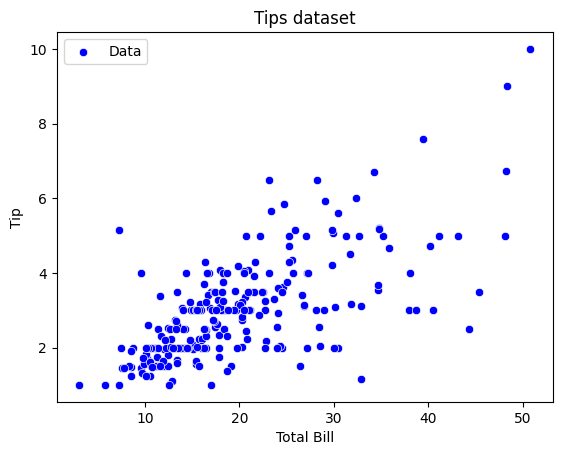

In [2]:
import matplotlib.pyplot as plt
sns.scatterplot(x="total_bill", y="tip", data=tips, color='blue', label='Data')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.legend()
plt.title('Tips dataset')
plt.show()

## 3.- Problem: Given a total bill, predict the tip

First, we will get the data for total_bill and tip:

In [3]:
x = tips[["total_bill"]].values
y = tips["tip"].values

It's very important that for evaluation we split our dataset into train and test:
We will use 80% of the data for training and 20% of the data for testing.

In [4]:
from sklearn.model_selection import train_test_split
# Split the data into training and test sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

**Question: How many samples (rows) do you have in the test set? How many samples do you have in the train set?**

Hint: you can use the .size function here.

## 4.- Create a Regression model and plot results:

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)

# Make predictions
y_pred = model.predict(x_test)

## 5.- Visualisation (qualitative evaluation)

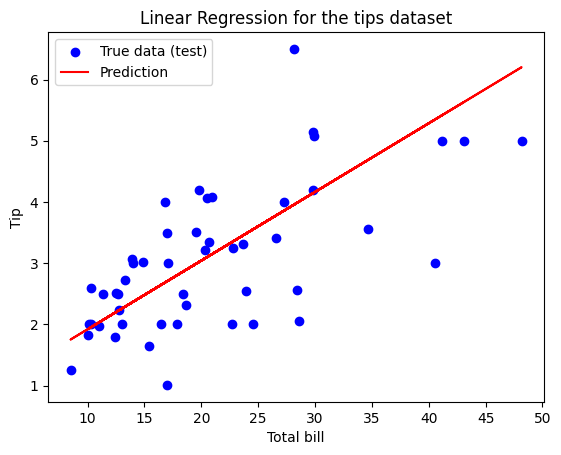

In [6]:
# Visualize the data and regression line
plt.scatter(x_test, y_test, color='blue', label='True data (test)')
plt.plot(x_test, y_pred, color='red', label='Prediction')
#plt.plot(x_test, y_pred, color='red', linewidth=3, label='Linear Regression')
plt.xlabel('Total bill')
plt.ylabel('Tip')
plt.legend()
plt.title('Linear Regression for the tips dataset')
plt.show()

## 6.- Quantitative evaluation

In [7]:
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared (R2) Score: {r2:.2f}')

Mean Squared Error: 0.86
R-squared (R2) Score: 0.35


**Question: If you run the notebook again (from the beginning) do you get the same results in terms of Mean Squared Error (MSE)? Why?**

# Decision Trees

For the decision trees task, we will be working with the iris dataset (flowers).

## 1.- Load the dataset

In [8]:
from sklearn.datasets import load_iris
iris = load_iris()

x, y = iris.data, iris.target

## 2.- Explore the dataset

Let's plot some of the data in the dataset.

First, we will plot the sepal length and the sepal width.
The sepal length is in index 0 in x, and sepal width is in index 1.

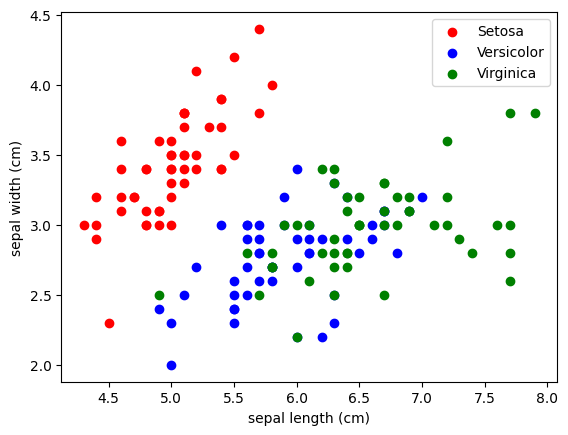

In [9]:
import matplotlib.pyplot as plt

plt.scatter(x[y == 0, 0], x[y == 0, 1], c = 'red', label = 'Setosa')
plt.scatter(x[y == 1, 0], x[y == 1, 1], c = 'blue', label = 'Versicolor')
plt.scatter(x[y == 2, 0], x[y == 2, 1], c = 'green', label = 'Virginica')
plt.xlabel(iris.feature_names[0])
plt.ylabel(ylabel=iris.feature_names[1])
plt.legend()
plt.show()

**Using the example above, plot the petal lenght and the petal width.**
Hint: The petal length is in index 2 in x, and sepal width is in index 3.

## 3.- Problem: Classify the iris dataset

First, we will have to split the dataset into test and train sets.

In [10]:
from sklearn.model_selection import train_test_split

# Split the data into training and test sets
x_train, x_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.2)

Print the number os samples (rows) in the train and test sets

In [11]:
print(x_train[:,0].size)
print(x_test[:,0].size)

120
30


## 4.- Create a Decision Tree model and plot results

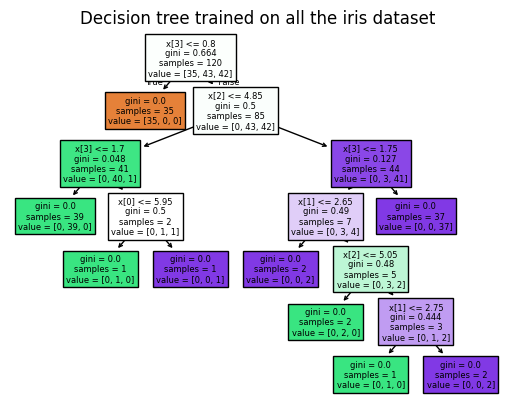

In [12]:
from sklearn import tree

# Train model
decision_tree = tree.DecisionTreeClassifier()
decision_tree = decision_tree.fit(x_train, y_train)


# Make predictions
y_pred = decision_tree.predict(x_test)

# Once trained, you can plot the tree with the plot_tree function:
plt.figure()
tree.plot_tree(decision_tree, filled=True)
plt.title("Decision tree trained on all the iris dataset")
plt.show()


## 5.- Quantitative evaluation

In [13]:
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

print(f'Mean Squared Error: {mse:.2f}')
print(f'R-squared (R2) Score: {r2:.2f}')
print(f'Accuracy:{accuracy:.2f}')

Mean Squared Error: 0.07
R-squared (R2) Score: 0.91
Accuracy:0.93


**Question: Predict the class of a new sample with the following values: [6.3, 2.9, 5.5, 2.3] and print the class name**

Hints:

To predict you will have to call the predict function with the values inside a list: [[6.3, 2.9, 5.5, 2.3]]

To print the class name, you may need to use iris.target_names

# Unsupervised learning: K-Means clustering

We will use now the K-Means method to classify the iris dataset.

## 1.- Load the dataset

In [14]:
from sklearn.datasets import load_iris

# Load Iris dataset
iris = load_iris()

## 2.- Problem: Classify the iris dataset

Since this is an unsupervised approach, we will not use the labels.

Print the number os samples (rows) in the train and test sets:

In [15]:
x = iris.data

print(x[:,0].size)

150


## 3.- Create a K-Means model and plot results¶

Please ignore the OMP_NNUM_THREADS warning.

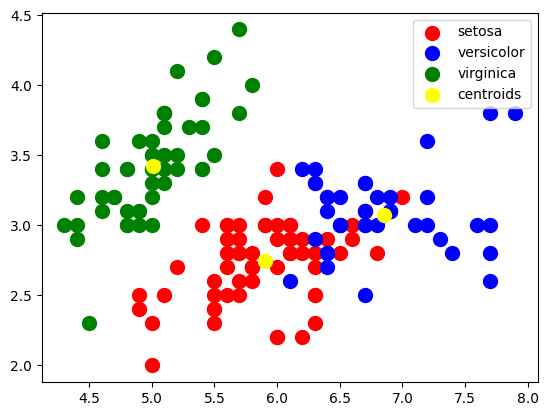

In [16]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


# Create and fit the model
model = KMeans(n_clusters = 3, max_iter = 300, n_init = 10, init='random')
model.fit(x)
y=model.predict(x)

# Visualise the clusters (groups)
plt.scatter(x[y == 0, 0], x[y == 0, 1], s = 100, c = 'red', label = 'setosa')
plt.scatter(x[y == 1, 0], x[y == 1, 1], s = 100, c = 'blue', label = 'versicolor')
plt.scatter(x[y == 2, 0], x[y == 2, 1], s = 100, c = 'green', label = 'virginica')
plt.scatter(model.cluster_centers_[:,0], model.cluster_centers_[:,1], s = 100, c = 'yellow', label = 'centroids')
plt.legend()


## 4.- Evaluation

In [17]:
inertia = model.inertia_

print(f'Inertia:{inertia:.2f}')

Inertia:78.85


## The Elbow method

**Task: Implement the Elbow method**

A good model is a model with a low inertia and a low number of clusters.
We already know that in the iris dataset there are 3 unique classes: setosa, versicolor and virginica. However, this will not be always the case (actually, in an unsupervised approach, this will never be the case).

To find the optimal number of clusters for a dataset, we will use the Elbow method and the inertia value.The Elbow method allows us to find the number of clusters for classification.

Use a for loop to run K-Means with different number of clusters from 1 to 10, and plot the value of inertia for each K number of clusters.

Then, find the point where the decrease in inertia begins to slow. You shoul observe that for the iris dataset this value is K=3.

# Additional Task

Use the life expectancy dataset to predict the life expectancy.
Choose one of the models above.

You will find the dataset here:

https://github.com/mwaskom/seaborn-data/blob/master/healthexp.csv